In [1]:
!pip -q install librosa soundfile praat-parselmouth

In [2]:
!wget -q --show-progress https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2
!tar -xjf LJSpeech-1.1.tar.bz2
!ls LJSpeech-1.1 | head

LJSpeech-1.1.tar.bz 100%[===================>]   2.56G  52.7MB/s    in 20s     
metadata.csv
README
wavs


In [3]:
import numpy as np, pandas as pd, librosa, matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import medfilt

ROOT = Path("LJSpeech-1.1"); WAV = ROOT / "wavs"
meta = pd.read_csv(ROOT / "metadata.csv", sep="|", header=None, quoting=3,
                   names=["id", "raw", "text"])
meta["text"] = meta["text"].fillna(meta["raw"]).astype(str).str.strip()
meta["n_words"] = meta["text"].str.split().str.len()

meta["label"] = np.where(meta.text.str.endswith("?"), "question",
                 np.where(meta.text.str.endswith("."), "statement", "other"))

# keep short/medium sentences, so length doesn't differ wildly between classes
meta = meta[(meta.label != "other") & meta.n_words.between(4, 15)].reset_index(drop=True)

# split questions into wh-questions vs yes/no questions
WH = ("what","who","whom","whose","where","when","why","which","how")
first = meta.text.str.split().str[0].str.lower().str.strip('"\'')
meta["qtype"] = np.where(meta.label == "statement", "statement",
                 np.where(first.isin(WH), "wh-question", "yes/no-question"))

print(meta.label.value_counts())
print(meta.qtype.value_counts())
meta.head()

label
statement    2901
question       28
Name: count, dtype: int64
qtype
statement          2901
yes/no-question      19
wh-question           9
Name: count, dtype: int64


,id,raw,text,n_words,label,qtype
0,LJ001-0002,in being comparatively modern.,in being comparatively modern.,4,statement,statement
1,LJ001-0008,has never been surpassed.,has never been surpassed.,4,statement,statement
2,LJ001-0013,than in the same operations with ugly ones.,than in the same operations with ugly ones.,8,statement,statement
3,LJ001-0020,"the ""lower-case"" being in fact invented in the...","the ""lower-case"" being in fact invented in the...",11,statement,statement
4,LJ001-0028,"but by printers in Strasburg, Basle, Paris, Lu...","but by printers in Strasburg, Basle, Paris, Lu...",11,statement,statement


In [4]:
SR, HOP, FRAME = 16000, 256, 1024   # 16 ms hop

def load_clip(clip_id):
    y, _ = librosa.load(WAV / f"{clip_id}.wav", sr=SR)
    return y

def prosody_contours(y):
    """F0 (Hz, NaN when unvoiced), energy (dB), and time axis."""
    f0, voiced, _ = librosa.pyin(y, fmin=70, fmax=400, sr=SR,
                                 frame_length=FRAME, hop_length=HOP)
    rms = librosa.feature.rms(y=y, frame_length=FRAME, hop_length=HOP)[0]
    energy_db = librosa.amplitude_to_db(rms, ref=np.max)
    n = min(len(f0), len(energy_db))
    t = librosa.times_like(f0[:n], sr=SR, hop_length=HOP)
    return t, f0[:n], energy_db[:n]

def pause_info(y, min_pause=0.15, top_db=35):
    """Internal pauses = silent gaps between speech chunks longer than min_pause sec."""
    iv = librosa.effects.split(y, top_db=top_db, frame_length=FRAME, hop_length=HOP)
    span = (iv[-1, 1] - iv[0, 0]) / SR                    # first speech -> last speech
    gaps = (iv[1:, 0] - iv[:-1, 1]) / SR
    pauses = gaps[gaps >= min_pause]
    return iv, span, pauses

def voiced_semitones(t, f0):
    """Voiced F0 converted to semitones relative to the clip's median (speaker-independent)."""
    m = ~np.isnan(f0)
    tv, fv = t[m], f0[m]
    if len(fv) < 8:
        return tv, np.array([])
    st = 12 * np.log2(fv / np.median(fv))
    return tv, medfilt(st, 5)          # median filter removes octave-jump glitches

def extract_features(clip_id, n_words):
    y = load_clip(clip_id)
    t, f0, e = prosody_contours(y)
    tv, st = voiced_semitones(t, f0)
    iv, span, pauses = pause_info(y)

    feats = dict(id=clip_id, duration=len(y) / SR)
    if len(st) >= 8:
        feats["f0_mean_hz"] = float(np.nanmean(f0))
        feats["f0_std_st"] = float(np.std(st))
        feats["f0_range_st"] = float(np.percentile(st, 95) - np.percentile(st, 5))
        feats["initial_level_st"] = float(np.mean(st[:5]))
        feats["final_level_st"] = float(np.mean(st[-5:]))
        sel = tv >= tv[-1] - 0.4                      # last 400 ms of voiced speech
        feats["final_slope_st_per_s"] = (float(np.polyfit(tv[sel], st[sel], 1)[0])
                                         if sel.sum() >= 4 else np.nan)
    feats["energy_std_db"] = float(np.std(e[e > -50]))
    feats["n_pauses"] = int(len(pauses))
    feats["pause_ratio"] = float(pauses.sum() / span) if span > 0 else 0.0
    feats["speaking_rate_wps"] = n_words / span       # words per second
    feats["articulation_rate_wps"] = n_words / max(span - pauses.sum(), 1e-3)
    return feats

# test on one clip
r = meta.iloc[0]
extract_features(r.id, r.n_words)

{'id': 'LJ001-0002',
 'duration': 1.8995625,
 'f0_mean_hz': 240.21711029859947,
 'f0_std_st': 4.718005353455573,
 'f0_range_st': 12.700000000000001,
 'initial_level_st': 6.379999999999998,
 'final_level_st': -3.000000000000001,
 'final_slope_st_per_s': -2.8751717032967057,
 'energy_std_db': 8.95000171661377,
 'n_pauses': 0,
 'pause_ratio': 0.0,
 'speaking_rate_wps': np.float64(2.1929824561403506),
 'articulation_rate_wps': np.float64(2.1929824561403506)}

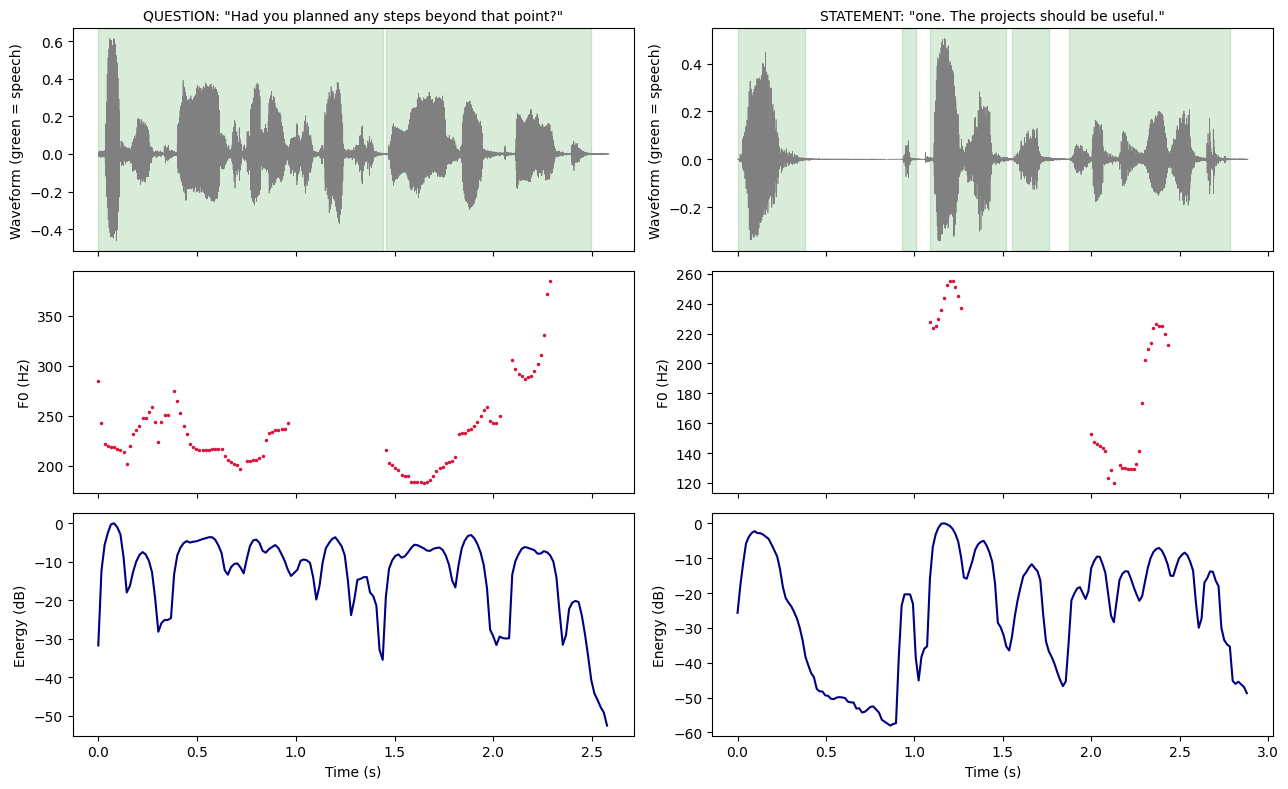

In [5]:
def plot_clip(clip_id, ax_col, axes, title):
    y = load_clip(clip_id)
    t, f0, e = prosody_contours(y)
    iv, span, pauses = pause_info(y)
    time = np.arange(len(y)) / SR

    axes[0, ax_col].plot(time, y, lw=0.5, color="gray")
    for s, en in iv:
        axes[0, ax_col].axvspan(s / SR, en / SR, color="green", alpha=0.15)
    axes[0, ax_col].set_title(title, fontsize=10)
    axes[0, ax_col].set_ylabel("Waveform (green = speech)")

    axes[1, ax_col].plot(t, f0, ".", ms=3, color="crimson")
    axes[1, ax_col].set_ylabel("F0 (Hz)")

    axes[2, ax_col].plot(t, e, color="navy")
    axes[2, ax_col].set_ylabel("Energy (dB)")
    axes[2, ax_col].set_xlabel("Time (s)")

# pick a short yes/no question and a short statement
yn = meta[(meta.qtype == "yes/no-question") & (meta.n_words <= 8)].sample(1, random_state=1).iloc[0]
st_ = meta[(meta.qtype == "statement") & (meta.n_words <= 8)].sample(1, random_state=1).iloc[0]

fig, axes = plt.subplots(3, 2, figsize=(13, 8), sharex="col")
plot_clip(yn.id, 0, axes, f'QUESTION: "{yn.text}"')
plot_clip(st_.id, 1, axes, f'STATEMENT: "{st_.text}"')
plt.tight_layout(); plt.savefig("single_clip_comparison.png", dpi=150); plt.show()

In [6]:
from IPython.display import Audio, display
display(Audio(str(WAV / f"{yn.id}.wav"))); display(Audio(str(WAV / f"{st_.id}.wav")))

statement 40 clips
yes/no-question 19 clips
wh-question 9 clips


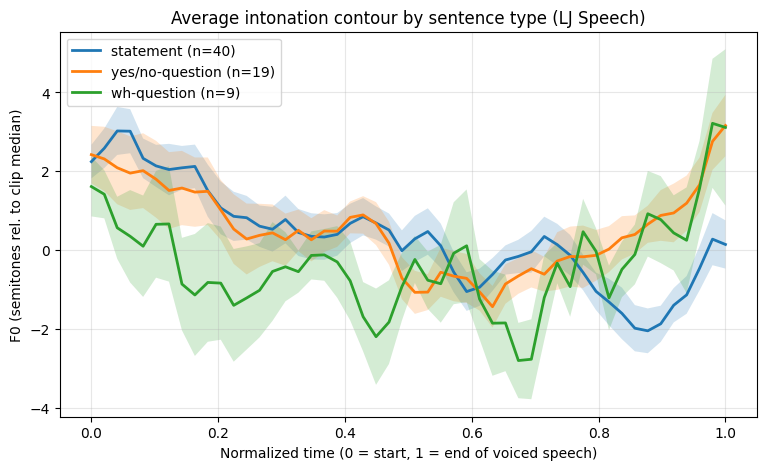

In [7]:
def normalized_contour(clip_id, grid=np.linspace(0, 1, 50)):
    y = load_clip(clip_id)
    t, f0, _ = prosody_contours(y)
    tv, st = voiced_semitones(t, f0)
    if len(st) < 8: return None
    tn = (tv - tv[0]) / (tv[-1] - tv[0])
    return np.interp(grid, tn, st)

N = 40   # clips per group (keeps runtime to a few minutes)
curves = {}
for g in ["statement", "yes/no-question", "wh-question"]:
    sub = meta[meta.qtype == g].sample(min(N, (meta.qtype == g).sum()), random_state=0)
    cs = [c for c in (normalized_contour(i) for i in sub.id) if c is not None]
    curves[g] = np.array(cs)
    print(g, len(cs), "clips")

grid = np.linspace(0, 1, 50)
plt.figure(figsize=(9, 5))
for g, c in curves.items():
    m, se = c.mean(0), c.std(0) / np.sqrt(len(c))
    plt.plot(grid, m, label=f"{g} (n={len(c)})", lw=2)
    plt.fill_between(grid, m - se, m + se, alpha=0.2)
plt.xlabel("Normalized time (0 = start, 1 = end of voiced speech)")
plt.ylabel("F0 (semitones rel. to clip median)")
plt.title("Average intonation contour by sentence type (LJ Speech)")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("average_contours.png", dpi=150); plt.show()

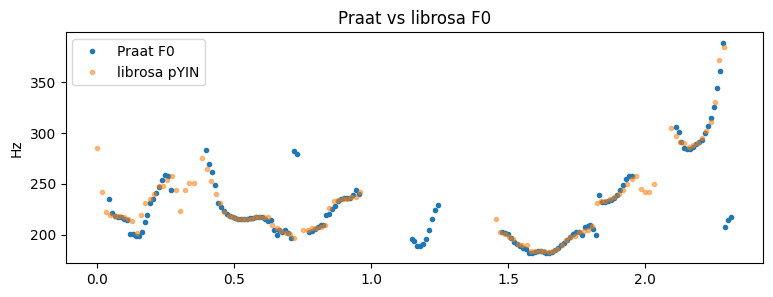

In [8]:
import parselmouth
snd = parselmouth.Sound(str(WAV / f"{yn.id}.wav"))
pitch = snd.to_pitch(pitch_floor=70, pitch_ceiling=400)
intensity = snd.to_intensity()
pt, pf = pitch.xs(), pitch.selected_array["frequency"]; pf[pf == 0] = np.nan
plt.figure(figsize=(9,3)); plt.plot(pt, pf, ".", label="Praat F0")
t, f0, _ = prosody_contours(load_clip(yn.id)); plt.plot(t, f0, ".", alpha=.5, label="librosa pYIN")
plt.legend(); plt.ylabel("Hz"); plt.title("Praat vs librosa F0"); plt.show()